# Movie Genre Classification & Attribute Analysis

Exploratory data analysis (EDA) and a baseline genre classifier for a dataset of 50,000 films.

**Sections**
1. Load & inspect the data
2. Distributions of the categorical attributes
3. Interactive explorers *(widgets and Plotly charts only render when the notebook is run locally, not on GitHub)*
4. Release-year trends
5. Genre classification (with a majority-class baseline)

> **Note on the data:** every category is almost perfectly evenly distributed and `Genre` is statistically independent of every other column, which is characteristic of a *synthetically generated* dataset. Read the results in section 5 with that in mind.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from ipywidgets import interact, widgets

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---- Configuration -------------------------------------------------------
DATA_PATH = Path("..") / "data" / "movie_genre_classification_final_2.csv"
FIGURES_DIR = Path("..") / "reports" / "figures"
SAVE_FIGURES = False   # set True to regenerate the PNGs used in the report
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

## 1. Load & inspect the data

In [2]:
data = pd.read_csv(DATA_PATH)
data.head()

,Title,Year,Director,Duration,Rating,Votes,Description,Language,Country,Budget_USD,BoxOffice_USD,Genre,Production_Company,Content_Rating,Lead_Actor,Num_Awards,Critic_Reviews
0,Movie 0,2018,R. Lee,134,5.835299,364931,A great movie,French,USA,148993080,422355909,Thriller,DreamWorks,G,Chris Evans,23,574
1,Movie 1,2008,S. Chen,144,9.150906,157534,A great movie,Spanish,USA,7192135,751873683,Thriller,Netflix,R,Tom Hanks,17,716
2,Movie 2,1994,A. Khan,155,4.397457,103674,A great movie,Spanish,India,136000288,52185367,Fantasy,Warner Bros,NC-17,Tom Hanks,2,976
3,Movie 3,2022,D. Patel,101,9.176136,45984,A great movie,Japanese,South Korea,122743699,814179800,Horror,Yash Raj Films,G,Amitabh Bachchan,9,39
4,Movie 4,1987,A. Khan,130,5.287297,499916,A great movie,English,India,63547377,193068686,Thriller,Pixar,R,Brad Pitt,23,343


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Title               50000 non-null  str    
 1   Year                50000 non-null  int64  
 2   Director            50000 non-null  str    
 3   Duration            50000 non-null  int64  
 4   Rating              50000 non-null  float64
 5   Votes               50000 non-null  int64  
 6   Description         50000 non-null  str    
 7   Language            50000 non-null  str    
 8   Country             50000 non-null  str    
 9   Budget_USD          50000 non-null  int64  
 10  BoxOffice_USD       50000 non-null  int64  
 11  Genre               50000 non-null  str    
 12  Production_Company  50000 non-null  str    
 13  Content_Rating      50000 non-null  str    
 14  Lead_Actor          50000 non-null  str    
 15  Num_Awards          50000 non-null  int64  
 16  Critic_Reviews 

In [4]:
# Number of distinct values per column
data.nunique()

Title                 50000
Year                     44
Director                 10
Duration                101
Rating                50000
Votes                 47553
Description               1
Language                  7
Country                   7
Budget_USD            49995
BoxOffice_USD         50000
Genre                     7
Production_Company       10
Content_Rating            5
Lead_Actor               10
Num_Awards               25
Critic_Reviews          990
dtype: int64

In [5]:
shortest = data.loc[data["Duration"].idxmin(), ["Title", "Duration"]]
longest = data.loc[data["Duration"].idxmax(), ["Title", "Duration"]]
print(f"Duration range: {data['Duration'].min()} to {data['Duration'].max()} minutes\n")
print("Shortest film:\n", shortest.to_string(), "\n")
print("Longest film:\n", longest.to_string())

Duration range: 80 to 180 minutes

Shortest film:
 Title       Movie 86
Duration          80 

Longest film:
 Title       Movie 142
Duration          180


## 2. Distributions of the categorical attributes

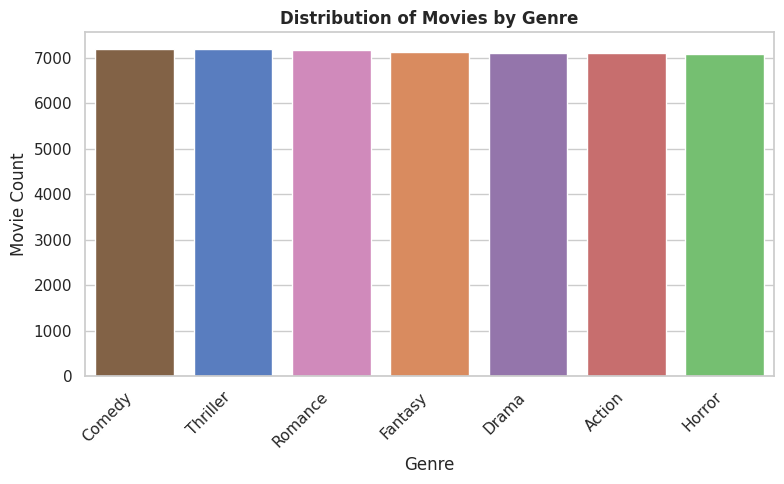

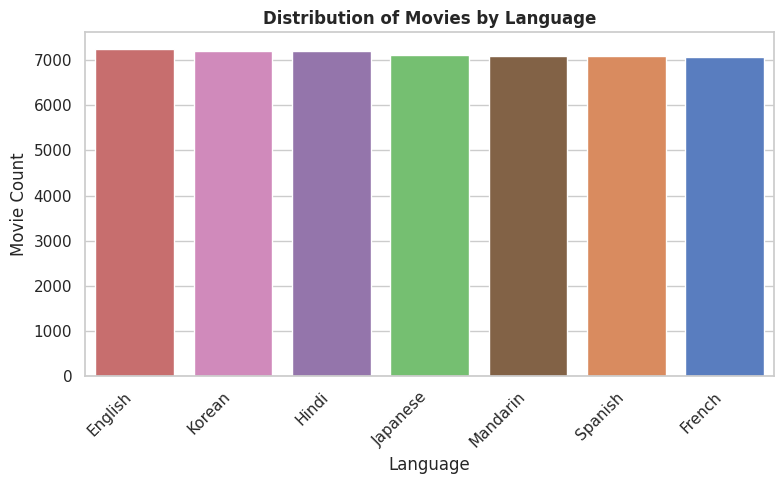

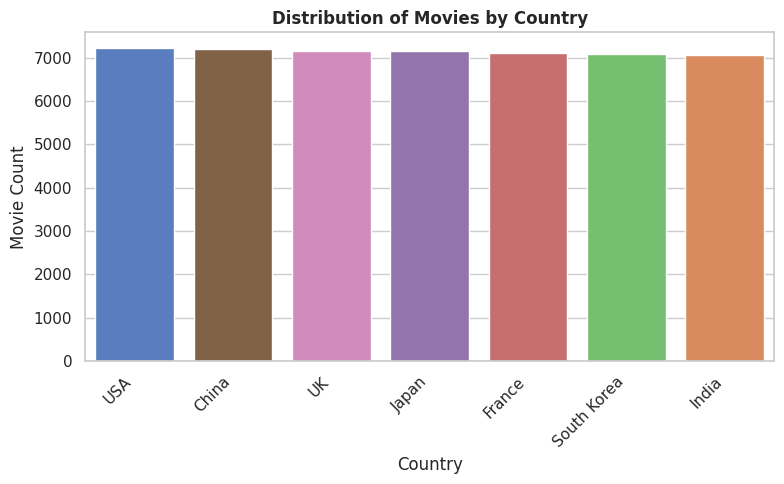

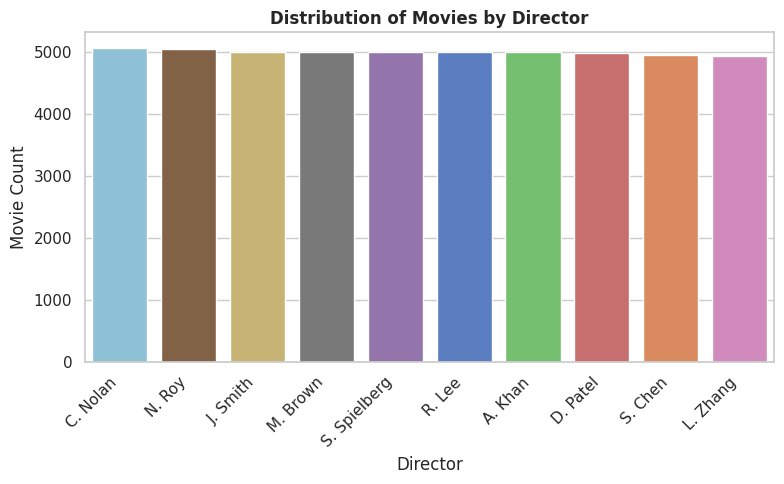

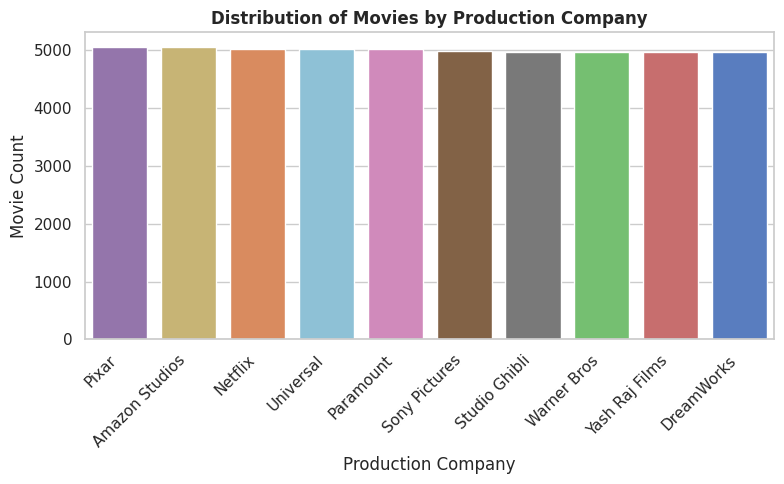

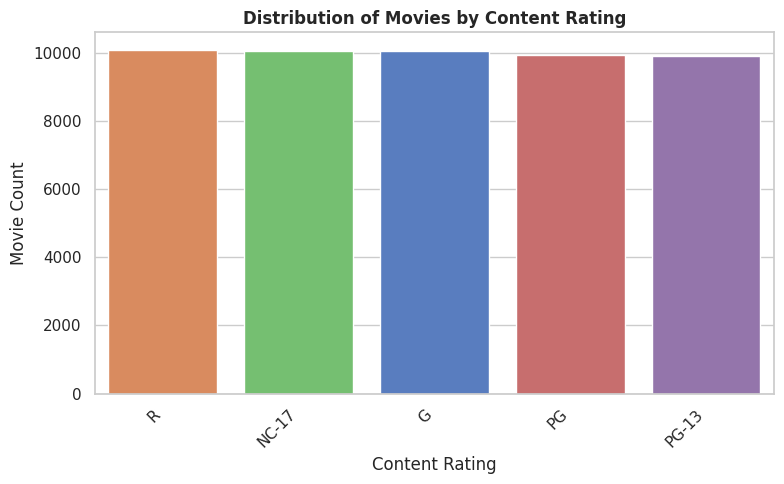

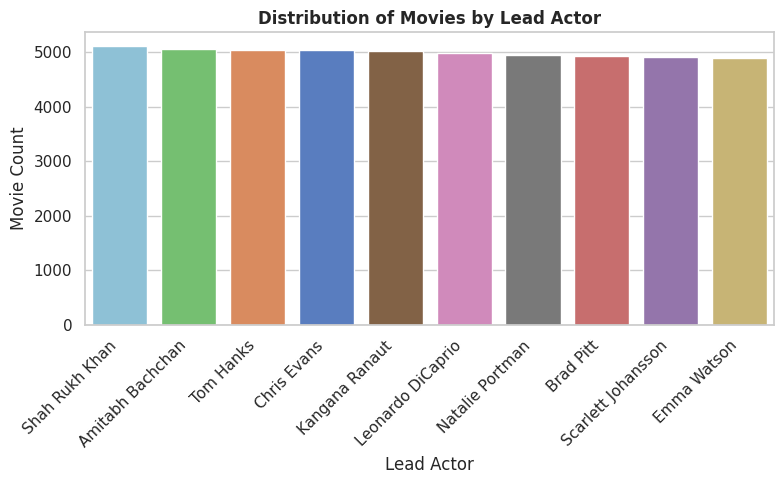

In [6]:
def plot_counts(col, data=data, save=SAVE_FIGURES):
    """Bar chart of film counts per category, sorted from most to least frequent."""
    order = data[col].value_counts().index
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.countplot(data=data, x=col, order=order, hue=col, palette="muted", legend=False, ax=ax)
    ax.set_title(f"Distribution of Movies by {col.replace('_', ' ')}", fontweight="bold")
    ax.set_xlabel(col.replace("_", " "))
    ax.set_ylabel("Movie Count")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    if save:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURES_DIR / f"{col.lower()}_distribution.png", dpi=300)
    plt.show()


categorical_cols_eda = ["Genre", "Language", "Country", "Director",
                        "Production_Company", "Content_Rating", "Lead_Actor"]
for col in categorical_cols_eda:
    plot_counts(col)

## 3. Interactive explorers

These need a live Python kernel (`jupyter lab`) and will appear blank on GitHub.

In [7]:
def plot_studios(country, genre):
    subset = data[(data["Country"] == country) & (data["Genre"] == genre)]
    fig = px.histogram(subset, x="Production_Company",
                       title=f"Movies in {country} | Genre: {genre}",
                       template="plotly_dark")
    fig.show()


interact(
    plot_studios,
    country=widgets.Dropdown(options=sorted(data["Country"].unique()), value="China", description="Country:"),
    genre=widgets.Dropdown(options=sorted(data["Genre"].unique()), value="Horror", description="Genre:"),
);

In [8]:
def plot_countries(language, genre):
    subset = data[(data["Language"] == language) & (data["Genre"] == genre)]
    fig = px.histogram(subset, x="Country",
                       title=f"Movies in {language} | Genre: {genre}",
                       template="plotly_dark")
    fig.show()


interact(
    plot_countries,
    language=widgets.Dropdown(options=sorted(data["Language"].unique()), value="English", description="Language:"),
    genre=widgets.Dropdown(options=sorted(data["Genre"].unique()), value="Action", description="Genre:"),
);

## 4. Release-year trends

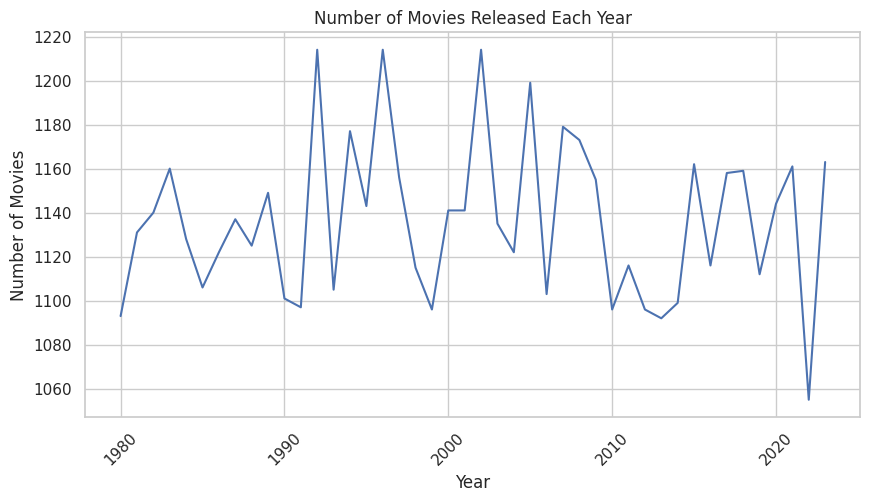

In [9]:
films_per_year = data["Year"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.lineplot(x=films_per_year.index, y=films_per_year.values)
plt.title("Number of Movies Released Each Year")
plt.xlabel("Year")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.show()

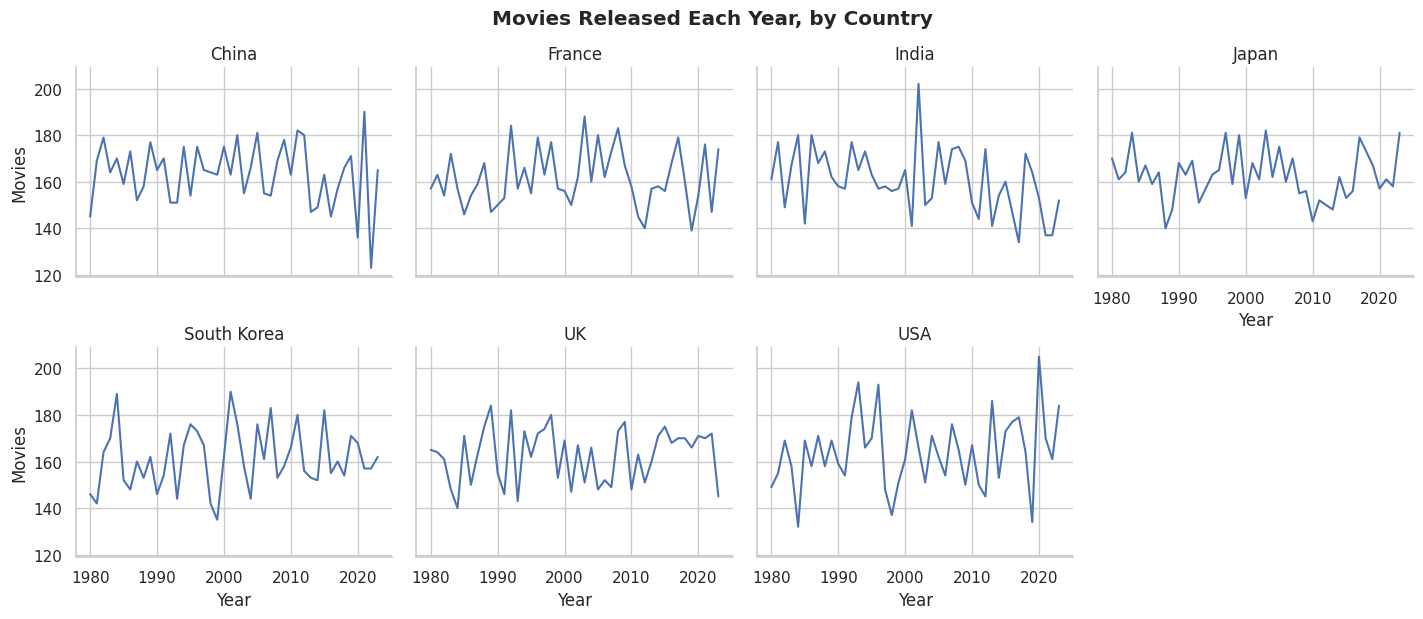

In [10]:
# One small panel per country
by_country = (data.groupby(["Country", "Year"]).size()
                  .rename("Movies").reset_index())
g = sns.relplot(data=by_country, x="Year", y="Movies", col="Country",
                col_wrap=4, kind="line", height=3, aspect=1.2)
g.set_titles("{col_name}")
g.figure.suptitle("Movies Released Each Year, by Country", y=1.03, fontweight="bold")
plt.show()

## 5. Genre classification

**Setup:** predict `Genre` from the numeric and categorical attributes using a one-hot-encoded Random Forest pipeline. `Title` is dropped because it is a unique identifier. `Description` is dropped because it carries no information in this file (it has a single constant value).

The model is compared with a **majority-class baseline** (`DummyClassifier`). With 7 roughly balanced genres, random guessing scores about 1/7 ≈ **14.3 %** accuracy, so that is the number to beat.

In [11]:
TARGET = "Genre"
features = data.drop(columns=[TARGET, "Title", "Description"])
target = data[TARGET]

numerical_cols = features.select_dtypes(include="number").columns.tolist()
categorical_cols = features.select_dtypes(exclude="number").columns.tolist()
print("Numerical:  ", numerical_cols)
print("Categorical:", categorical_cols)

X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, random_state=RANDOM_STATE, stratify=target
)

Numerical:   ['Year', 'Duration', 'Rating', 'Votes', 'Budget_USD', 'BoxOffice_USD', 'Num_Awards', 'Critic_Reviews']
Categorical: ['Director', 'Language', 'Country', 'Production_Company', 'Content_Rating', 'Lead_Actor']


In [12]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numerical_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols),
])

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f"Majority-class baseline accuracy: {accuracy_score(y_test, baseline.predict(X_test)):.3f}")
print(f"Random Forest accuracy:           {accuracy_score(y_test, y_pred):.3f}")
print(f"Chance level (1 / n_genres):      {1 / target.nunique():.3f}\n")
print(classification_report(y_test, y_pred))

Majority-class baseline accuracy: 0.144
Random Forest accuracy:           0.144
Chance level (1 / n_genres):      0.143

              precision    recall  f1-score   support

      Action       0.15      0.17      0.16      1422
      Comedy       0.15      0.16      0.15      1440
       Drama       0.15      0.15      0.15      1423
     Fantasy       0.14      0.14      0.14      1425
      Horror       0.14      0.13      0.13      1418
     Romance       0.14      0.14      0.14      1434
    Thriller       0.13      0.12      0.13      1438

    accuracy                           0.14     10000
   macro avg       0.14      0.14      0.14     10000
weighted avg       0.14      0.14      0.14     10000



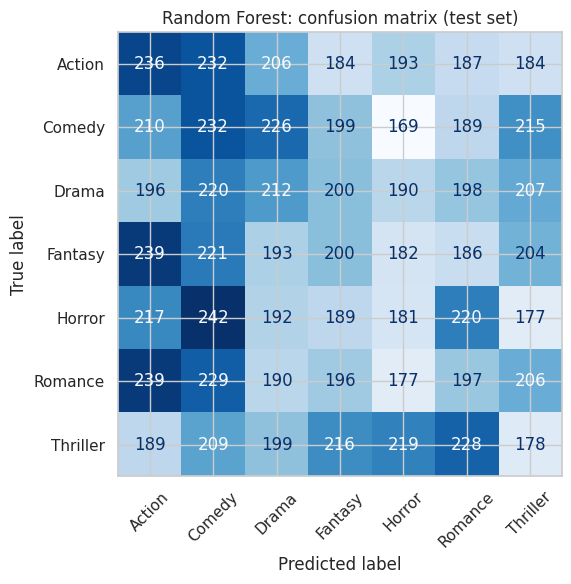

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, xticks_rotation=45,
                                        colorbar=False, cmap="Blues")
ax.set_title("Random Forest: confusion matrix (test set)")
plt.tight_layout()
plt.show()

### Interpretation

* Accuracy is statistically indistinguishable from chance (about 14 %), so **none of the attributes in this dataset predicts genre**. This is consistent with the data being synthetic: genre is independent of rating, budget, box office, director, studio and so on.
* An earlier version of the dataset (`movie_genre_classification_final.csv`) contained a `Description` column whose text mapped one-to-one to genre. A model using it scored 100 % accuracy. That was **target leakage**, not a good model, and it is why `Description` is excluded here.
* To build a meaningful classifier, use real data with genuinely informative features (for example real plot summaries) and keep a baseline in every evaluation.